# Mastery Progression — evaluation and error analysis

This notebook uses the existing **five-seed Mastery Progression** results and real prediction traces. It compares `fixed_early`, `fixed_late`, and `mastery` through task accuracy, transitions, per-question forgetting/recovery, and error patterns.

The model, dataset, and completed training runs are unchanged. The main evaluation splits are held-out ID-dev (excluded from mastery-transition decisions) and OOD-dev. No synthetic data or new training is used.

In [1]:
from pathlib import Path
import json
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_REL = Path("outputs/medium_world/dataset")
OUT_REL = Path("outputs/medium_world/experiments/mastery_progression")
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.medium_visual_world.prediction_tracking import (
    load_trace, compare_two, compare_three, summarize_changes, scene_context
)

DATA_DIR = PROJECT_ROOT / DATA_REL
EXPERIMENT_DIR = PROJECT_ROOT / OUT_REL
RESULTS_FILE = EXPERIMENT_DIR / "schedule_comparison.json"
TRACE_DIR = EXPERIMENT_DIR / "prediction_traces"
DATASET_FILES = {
    "id_dev": DATA_DIR / "id_dev.jsonl",
    "ood_dev": DATA_DIR / "ood_dev.jsonl",
}
TRANSITION_CSV = EXPERIMENT_DIR / "mastery_transition_accuracy.csv"
TRANSITION_FIG = EXPERIMENT_DIR / "mastery_transition_accuracy.png"
CHANGE_SUMMARY_CSV = EXPERIMENT_DIR / "prediction_change_summary.csv"
CHANGE_QUESTIONS_CSV = EXPERIMENT_DIR / "prediction_changes_by_example.csv.gz"
FORGETTING_FIG = EXPERIMENT_DIR / "prediction_forgetting_by_curriculum.png"
ERROR_CHECKPOINT_CSV = EXPERIMENT_DIR / "prediction_error_checkpoints.csv"
ERROR_GROUP_CSV = EXPERIMENT_DIR / "prediction_error_subgroups.csv"
ERROR_TRANSITION_CSV = EXPERIMENT_DIR / "prediction_error_transitions.csv"
BINDING_RECALL_FIG = EXPERIMENT_DIR / "prediction_binding_positive_recall.png"
BINDING_SPECIFICITY_FIG = EXPERIMENT_DIR / "prediction_binding_negative_specificity.png"
BINDING_COMPLEXITY_FIG = EXPERIMENT_DIR / "prediction_binding_by_object_count.png"

def trace_path(run):
    # Prefer traces in the experiment folder, even if moved after training.
    filename = f"{run['policy']}_seed_{int(run['seed'])}.npz"
    relocated = TRACE_DIR / filename
    if relocated.is_file():
        return relocated
    recorded = run.get("prediction_trace")
    if recorded:
        original = Path(str(recorded).replace("\\", "/"))
        if not original.is_absolute():
            original = PROJECT_ROOT / original
        if original.is_file():
            return original
    return relocated

if not RESULTS_FILE.is_file():
    raise FileNotFoundError(f"Mastery training results are missing: {RESULTS_FILE}")
report = json.loads(RESULTS_FILE.read_text(encoding="utf-8"))
runs = sorted((r for r in report.get("runs", []) if r.get("status") == "completed"),
              key=lambda r: (int(r["seed"]), str(r["policy"])))
if not runs:
    raise ValueError("No completed mastery training runs in schedule_comparison.json")
if len({(r["seed"], r["policy"]) for r in runs}) != len(runs):
    raise ValueError("Duplicate seed-policy results found")
print("Experiment:", EXPERIMENT_DIR.relative_to(PROJECT_ROOT))
print("Completed runs:", len(runs))
print("Policies:", sorted({r["policy"] for r in runs}))
print("Seeds:", sorted({r["seed"] for r in runs}))
print("Per-question trace files present:", len(list(TRACE_DIR.glob("*.npz"))))
print("Trace folder:", TRACE_DIR)
print("Run trace paths resolved:", sum(trace_path(r).is_file() for r in runs), "/", len(runs))

Experiment: outputs\medium_world\experiments\mastery_progression
Completed runs: 15
Policies: ['fixed_early', 'fixed_late', 'mastery']
Seeds: [42, 43, 44, 45, 46]
Per-question trace files present: 15
Trace folder: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\medium_world\experiments\mastery_progression\prediction_traces
Run trace paths resolved: 15 / 15


## 1. Actual changes in task accuracy around stage transitions

The original mastery results already contain evaluation histories every 100 optimizer updates. We compare the latest saved evaluation **at or before** each actual stage transition with the first evaluation **after** it, and examine the lowest accuracy observed before the next transition.

This is a real retrospective analysis, even when per-question traces were not saved. A decline in accuracy does **not** tell us which individual questions were forgotten.

In [2]:
TASKS = ("color", "shape", "conjunction", "pair")
SPLITS = ("heldout_dev", "progress_dev", "id_dev", "ood_dev")

def task_accuracy(snapshot, split, task):
    return snapshot.get(split, {}).get("by_template", {}).get(task)

rows = []
for run in runs:
    history = sorted(run["history"], key=lambda h: h["step"])
    transitions = sorted(run.get("transitions", []), key=lambda event: event["step"])
    for index, event in enumerate(transitions):
        step = int(event["step"])
        before = [h for h in history if int(h["step"]) <= step]
        after = [h for h in history if int(h["step"]) > step]
        if not before or not after:
            continue
        left, right = before[-1], after[0]
        next_boundary = (int(transitions[index + 1]["step"])
                         if index + 1 < len(transitions) else int(history[-1]["step"]))
        during = [h for h in after if int(h["step"]) <= next_boundary]
        if not during:
            during = [right]
        for split in SPLITS:
            for task in TASKS:
                pre, post = task_accuracy(left, split, task), task_accuracy(right, split, task)
                if pre is None or post is None:
                    continue
                accuracies = [task_accuracy(h, split, task) for h in during]
                accuracies = [a for a in accuracies if a is not None]
                if not accuracies:
                    continue
                rows.append({
                    "seed": run["seed"], "policy": run["policy"], "split": split,
                    "task": task, "stage_from": event["from"], "stage_to": event["to"],
                    "reason": event["reason"], "transition_step": step,
                    "before_step": int(left["step"]), "after_step": int(right["step"]),
                    "before_accuracy": pre, "after_accuracy": post,
                    "immediate_change_pp": 100 * (post - pre),
                    "worst_decline_pp": max(0.0, 100 * (pre - min(accuracies))),
                    "stage_end_step": int(during[-1]["step"]),
                    "stage_end_accuracy": accuracies[-1],
                    "final_accuracy": task_accuracy(history[-1], split, task),
                })

aggregate = pd.DataFrame(rows)
if aggregate.empty:
    raise ValueError("No stage-transition accuracy metrics were found in the mastery histories")
aggregate.to_csv(TRANSITION_CSV, index=False)
print("Saved:", TRANSITION_CSV.name)

focus = aggregate[(aggregate["stage_to"] == "binding") &
                  (aggregate["split"] == "heldout_dev")]
print("Accuracy change immediately after entering Binding, averaged over seeds (percentage points):")
display(focus.groupby(["policy", "task"])[["immediate_change_pp", "worst_decline_pp"]]
        .agg(["mean", "std"]).round(2))
print("Real transition steps and reasons:")
display(aggregate[["seed", "policy", "stage_from", "stage_to", "transition_step", "reason"]]
        .drop_duplicates().sort_values(["seed", "policy", "transition_step"]).reset_index(drop=True))

Saved: mastery_transition_accuracy.csv
Accuracy change immediately after entering Binding, averaged over seeds (percentage points):


immediate_change_pp       worst_decline_pp       
                                       mean   std             mean    std
policy      task                                                         
fixed_early color                      0.31  1.18             0.47   0.70
            conjunction               -1.72  2.67             2.97   1.50
            pair                       1.82  3.98             1.82   2.22
            shape                      0.30  4.01             2.52   2.54
fixed_late  color                     -0.62  1.16             1.72   1.16
            conjunction               -2.81  2.68             4.69   2.65
            pair                       6.61  5.36             0.33   0.74
            shape                     -1.48  3.19             5.19   3.14
mastery     color                     -2.81  4.08             8.12  10.07
            conjunction               -5.00  7.04             6.09   6.48
            pair                       5.95  4.65             0.50   1.11
            shape                     -3.26  4.01             5.04   3.07

Real transition steps and reasons:


,seed,policy,stage_from,stage_to,transition_step,reason
0,42,fixed_early,attributes,conjunction,1400,fixed_step
1,42,fixed_early,conjunction,binding,2200,fixed_step
2,42,fixed_early,binding,common_mixed,7200,common_phase
3,42,fixed_late,attributes,conjunction,3000,fixed_step
4,42,fixed_late,conjunction,binding,5000,fixed_step
5,42,fixed_late,binding,common_mixed,7200,common_phase
6,42,mastery,attributes,conjunction,2700,mastery
7,42,mastery,conjunction,binding,3500,mastery
8,42,mastery,binding,common_mixed,7200,common_phase
9,43,fixed_early,attributes,conjunction,1400,fixed_step


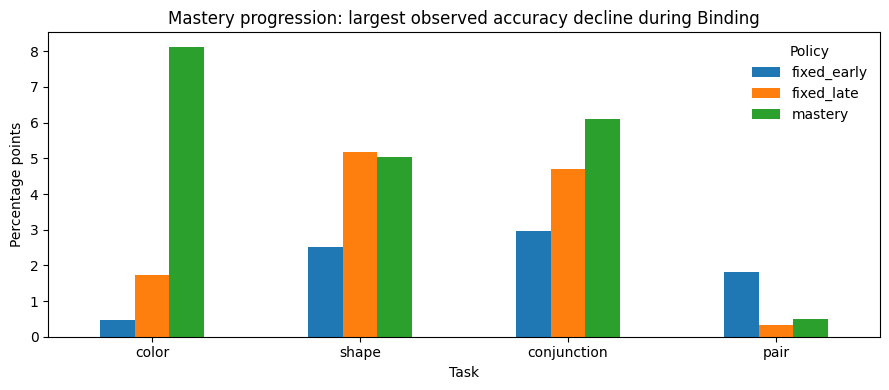

Saved: mastery_transition_accuracy.png


In [3]:
view = focus.pivot_table(index="task", columns="policy", values="worst_decline_pp", aggfunc="mean")
order = [t for t in TASKS if t in view.index]
if not view.empty:
    ax = view.loc[order].plot(kind="bar", figsize=(9, 4))
    ax.set(title="Mastery progression: largest observed accuracy decline during Binding",
           xlabel="Task", ylabel="Percentage points", ylim=(0, None))
    ax.legend(title="Policy", frameon=False)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(TRANSITION_FIG, dpi=180)
    plt.show()
    print("Saved:", TRANSITION_FIG.name)

## 2. Load actual per-question prediction traces, if available

A trace file must have been written **while that seed and curriculum were training**, or generated by reevaluating a saved model checkpoint. The historical JSON only stores aggregate metrics; it does not contain individual answers.

This cell matches traces to completed `mastery_progression` runs, verifies their metadata and, when traces exist, checks question IDs and labels against the original development datasets. A missing trace is **not** replaced by simulated predictions.

In [4]:
traces = {}
missing = []
expected_hashes = report.get("dataset_hashes", {})
for run in runs:
    seed, policy = int(run["seed"]), str(run["policy"])
    path = trace_path(run)
    if not path.is_file():
        missing.append((seed, policy, str(path)))
        continue
    trace = load_trace(path)
    meta = trace["metadata"]
    if int(meta.get("seed", -1)) != seed or meta.get("policy") != policy:
        raise ValueError(f"Trace metadata mismatch: {path}")
    recorded_hashes = meta.get("dataset_hashes", {})
    for filename in ("id_dev.jsonl", "ood_dev.jsonl"):
        if filename in recorded_hashes and filename in expected_hashes:
            if recorded_hashes[filename] != expected_hashes[filename]:
                raise ValueError(f"Dataset hash mismatch for {filename} in {path}")
    traces[(seed, policy)] = trace

metadata_by_split = {}
if traces:
    for split in ("id_dev", "ood_dev"):
        dataset_path = DATASET_FILES[split]
        if not dataset_path.is_file():
            raise FileNotFoundError(f"Prediction traces require original dataset metadata: {dataset_path}")
        actual_hash = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
        if split + ".jsonl" in expected_hashes and actual_hash != expected_hashes[split + ".jsonl"]:
            raise ValueError(f"Dataset differs from the mastery training results: {split}.jsonl")
        with dataset_path.open(encoding="utf-8") as stream:
            metadata_by_split[split] = [json.loads(line) for line in stream if line.strip()]

    # Match the mastery notebook's scene-level progress / held-out partition.
    id_rows = metadata_by_split["id_dev"]
    all_scenes = sorted({row["scene_id"] for row in id_rows},
                        key=lambda scene: hashlib.sha256(f"mastery-v1:{scene}".encode()).hexdigest())
    progress_scenes = set(all_scenes[:len(all_scenes) // 2])
    heldout_scenes = set(all_scenes[len(all_scenes) // 2:])
    print(f"Mastery ID-dev split: {len(progress_scenes)} progress scenes, "
          f"{len(heldout_scenes)} held-out scenes")

    for (seed, policy), trace in traces.items():
        for split, block in trace["splits"].items():
            if split not in metadata_by_split:
                raise ValueError(f"Unknown evaluation split {split} in {policy}, seed {seed}")
            source = metadata_by_split[split]
            ids = [r["id"] for r in source]
            labels = np.array([r["label"] for r in source], dtype=np.uint8)
            tasks = [r["template"] for r in source]
            if (list(block["ids"]) != ids or not np.array_equal(block["labels"], labels)
                    or list(block["tasks"]) != tasks):
                raise ValueError(f"Trace questions are not aligned to {split}: {policy}, seed {seed}")
            expected_run = next(r for r in runs if int(r["seed"]) == seed and r["policy"] == policy)
            if len(ids) != expected_run["final"][split]["n"]:
                raise ValueError(f"Trace question count differs from run metrics: {policy}, {seed}, {split}")
            steps, preds, probs = block["steps"], block["predictions"], block["probabilities"]
            if int(steps[0]) != 0 or int(steps[-1]) != int(expected_run["steps_run"]):
                raise ValueError(f"Trace missing initial/final checkpoint: {policy}, {seed}, {split}")
            if (len(steps) == 0 or np.any(np.diff(steps) <= 0) or
                    preds.shape != (len(steps), len(ids)) or probs.shape != preds.shape or
                    not np.isfinite(probs).all() or (probs < 0).any() or (probs > 1).any()):
                raise ValueError(f"Invalid trace shape, steps, or probabilities: {policy}, seed {seed}")

print(f"Matched real prediction traces: {len(traces)}/{len(runs)} completed runs")
if missing:
    print("Missing traces for:", missing)
if not traces:
    print("No historical per-question predictions are available in this experiment directory.")
    print("The real accuracy-transition analysis above is complete, but")
    print("retained / forgotten / newly learned / recovered cannot be calculated yet.")
    print("To obtain them, record traces in a NEW mastery training run with the patched")
    print("mastery_progression.ipynb, or reevaluate compatible saved checkpoints.")

Mastery ID-dev split: 256 progress scenes, 256 held-out scenes
Matched real prediction traces: 15/15 completed runs


## 3. Per-question retained, forgotten, newly learned, and recovered

Only real saved predictions are used below. For each actual transition, the first comparison is between the latest recorded checkpoint at or before the transition and the next recorded checkpoint. Recovery is assessed at the **final saved checkpoint** of the same run. The same question IDs are compared throughout.

In [5]:
def select_questions(block, indices):
    """Select existing question predictions without training or reevaluation."""
    indices = np.asarray(indices, dtype=int)
    return {
        "ids": block["ids"][indices], "tasks": block["tasks"][indices],
        "labels": block["labels"][indices], "steps": block["steps"],
        "predictions": block["predictions"][:, indices],
        "probabilities": block["probabilities"][:, indices],
    }

summaries, question_changes = [], []
trace_blocks = {}
for run in runs:
    seed, policy = int(run["seed"]), str(run["policy"])
    trace = traces.get((seed, policy))
    if trace is None:
        continue
    blocks = dict(trace["splits"])
    if "id_dev" in blocks:
        index_progress = [i for i, row in enumerate(metadata_by_split["id_dev"])
                          if row["scene_id"] in progress_scenes]
        index_heldout = [i for i, row in enumerate(metadata_by_split["id_dev"])
                         if row["scene_id"] in heldout_scenes]
        blocks["progress_dev"] = select_questions(blocks["id_dev"], index_progress)
        blocks["heldout_dev"] = select_questions(blocks["id_dev"], index_heldout)
    trace_blocks[(seed, policy)] = blocks
    for transition in run.get("transitions", []):
        for split, block in blocks.items():
            steps = [int(t) for t in block["steps"]]
            before_steps = [t for t in steps if t <= int(transition["step"])]
            after_steps = [t for t in steps if t > int(transition["step"])]
            if not before_steps or not after_steps:
                continue
            before, after, final = before_steps[-1], after_steps[0], steps[-1]
            changes = (compare_three(block, before, after, final)
                       if final > after else compare_two(block, before, after))
            source_split = "id_dev" if split in ("progress_dev", "heldout_dev") else split
            changes = scene_context(changes, metadata_by_split[source_split])
            event = {"seed": seed, "policy": policy, "split": split,
                     "stage_from": transition["from"], "stage_to": transition["to"],
                     "reason": transition["reason"], "transition_step": int(transition["step"])}
            changes = changes.assign(**event)
            question_changes.append(changes)
            values = summarize_changes(changes)
            values = values.assign(**event, before_step=before, after_step=after, final_step=final)
            summaries.append(values)

change_summary = pd.concat(summaries, ignore_index=True) if summaries else pd.DataFrame()
questions = pd.concat(question_changes, ignore_index=True) if question_changes else pd.DataFrame()
if not change_summary.empty:
    change_summary.to_csv(CHANGE_SUMMARY_CSV, index=False)
    questions.to_csv(CHANGE_QUESTIONS_CSV, index=False, compression="gzip")
    print("Saved:", CHANGE_SUMMARY_CSV.name, "and", CHANGE_QUESTIONS_CSV.name)
    print("Per-question categories for the transition into Binding (held-out ID-dev):")
    subset = change_summary[(change_summary["split"] == "heldout_dev") &
                            (change_summary["stage_to"] == "binding") &
                            (change_summary["task"] != "all")]
    display(subset[["seed", "policy", "task", "before_step", "after_step",
                    "retained", "forgotten", "newly_learned", "still_incorrect",
                    "recovered", "forgetting_rate", "correctness_churn"]].head(16).round(3))
else:
    print("No real question-level change categories could be calculated.")

Saved: prediction_change_summary.csv and prediction_changes_by_example.csv.gz
Per-question categories for the transition into Binding (held-out ID-dev):


,seed,policy,task,before_step,after_step,retained,forgotten,newly_learned,still_incorrect,recovered,forgetting_rate,correctness_churn
30,42,fixed_early,color,2200,2300,128,0,0,0,0,0.000,0.000
31,42,fixed_early,conjunction,2200,2300,97,4,1,26,2,0.040,0.039
32,42,fixed_early,pair,2200,2300,39,17,13,52,9,0.304,0.248
33,42,fixed_early,shape,2200,2300,65,12,16,42,3,0.156,0.207
81,42,fixed_late,color,5000,5100,127,1,0,0,0,0.008,0.008
82,42,fixed_late,conjunction,5000,5100,100,9,2,17,7,0.083,0.086
83,42,fixed_late,pair,5000,5100,45,10,26,40,5,0.182,0.298
84,42,fixed_late,shape,5000,5100,73,10,10,42,10,0.120,0.148
132,42,mastery,color,3500,3600,126,2,0,0,2,0.016,0.016
133,42,mastery,conjunction,3500,3600,99,3,2,24,2,0.029,0.039


## 4. Compare policies and investigate hard questions

When real traces exist, use the mastery experiment's **held-out ID-dev** questions to compare policy means **across seeds**, rather than treating hundreds of questions as independent runs. Use scene metadata to investigate whether more complex images are associated with forgetting.

Question-level changes after entering Binding (seed means ± SD):


forgetting_rate        correctness_churn         \
                                   mean    std              mean    std   
policy      task                                                          
fixed_early color                 0.002  0.004             0.006  0.010   
            conjunction           0.043  0.016             0.052  0.014   
            pair                  0.333  0.130             0.326  0.146   
            shape                 0.114  0.063             0.136  0.055   
fixed_late  color                 0.009  0.009             0.012  0.007   
            conjunction           0.067  0.022             0.081  0.013   
            pair                  0.363  0.128             0.407  0.094   
            shape                 0.162  0.060             0.181  0.081   
mastery     color                 0.031  0.040             0.034  0.039   
            conjunction           0.094  0.097             0.103  0.093   
            pair                  0.379  0.084             0.413  0.107   
            shape                 0.196  0.053             0.210  0.061   

                        recovery_rate_among_forgotten         
                                                 mean    std  
policy      task                                              
fixed_early color                               1.000    NaN  
            conjunction                         0.630  0.083  
            pair                                0.589  0.139  
            shape                               0.656  0.255  
fixed_late  color                               0.500  0.577  
            conjunction                         0.552  0.280  
            pair                                0.464  0.184  
            shape                               0.775  0.141  
mastery     color                               1.000  0.000  
            conjunction                         0.624  0.170  
            pair                                0.476  0.164  
            shape                               0.788  0.181

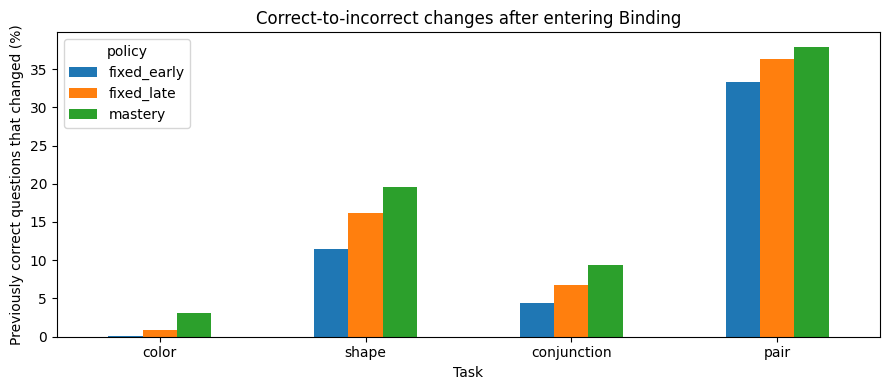

Saved: prediction_forgetting_by_curriculum.png


In [6]:
if not change_summary.empty:
    focus = change_summary[(change_summary["split"] == "heldout_dev") &
                           (change_summary["stage_to"] == "binding") &
                           (change_summary["task"].isin(TASKS))]
    group = focus.groupby(["policy", "task"])[
        ["forgetting_rate", "correctness_churn", "recovery_rate_among_forgotten"]
    ].agg(["mean", "std"])
    print("Question-level changes after entering Binding (seed means ± SD):")
    display(group.round(3))
    pivot = focus.pivot_table(index="task", columns="policy", values="forgetting_rate")
    pivot = pivot.reindex([t for t in TASKS if t in pivot.index])
    ax = pivot.mul(100).plot(kind="bar", figsize=(9, 4))
    ax.set(title="Correct-to-incorrect changes after entering Binding",
           xlabel="Task", ylabel="Previously correct questions that changed (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FORGETTING_FIG, dpi=180)
    plt.show()
    print("Saved:", FORGETTING_FIG.name)
else:
    print("Question-level transition analysis requires saved prediction traces.")

## 5. Prediction errors throughout training

For each real checkpoint, calculate the confusion matrix, positive recall, negative specificity, and predicted-positive rate **separately for each task**. These distinguish genuine detection of positive Binding examples from a bias toward answering No. Held-out ID-dev is the main ID comparison; OOD-dev contains only Binding questions.

In [7]:
def binary_scores(labels, predictions, probabilities):
    labels = np.asarray(labels, dtype=np.uint8)
    predictions = np.asarray(predictions, dtype=np.uint8)
    probabilities = np.asarray(probabilities, dtype=float)
    n = len(labels)
    tp = int(((labels == 1) & (predictions == 1)).sum())
    fn = int(((labels == 1) & (predictions == 0)).sum())
    tn = int(((labels == 0) & (predictions == 0)).sum())
    fp = int(((labels == 0) & (predictions == 1)).sum())
    safe = np.clip(probabilities, 1e-7, 1 - 1e-7)
    loss = -(labels * np.log(safe) + (1 - labels) * np.log1p(-safe)).mean() if n else np.nan
    return {"n": n, "tp": tp, "fn": fn, "tn": tn, "fp": fp,
            "accuracy": (tp + tn) / n if n else np.nan,
            "positive_recall": tp / (tp + fn) if tp + fn else np.nan,
            "negative_specificity": tn / (tn + fp) if tn + fp else np.nan,
            "predicted_positive_rate": float((predictions == 1).mean()) if n else np.nan,
            "bce": float(loss)}

checkpoint_rows = []
for (seed, policy), blocks in trace_blocks.items():
    for split in ("progress_dev", "heldout_dev", "id_dev", "ood_dev"):
        if split not in blocks:
            continue
        block = blocks[split]
        tasks = np.asarray(block["tasks"])
        for i, step in enumerate(block["steps"]):
            for task in sorted(set(tasks)):
                mask = tasks == task
                stats = binary_scores(block["labels"][mask],
                                      block["predictions"][i, mask],
                                      block["probabilities"][i, mask])
                checkpoint_rows.append({"seed": seed, "policy": policy, "split": split,
                                        "step": int(step), "task": task, **stats})
checkpoint_metrics = pd.DataFrame(checkpoint_rows)
if not checkpoint_metrics.empty:
    checkpoint_metrics.to_csv(ERROR_CHECKPOINT_CSV, index=False)
    print("Saved:", ERROR_CHECKPOINT_CSV.name)
    final_metrics = checkpoint_metrics[(checkpoint_metrics["split"].isin(("heldout_dev", "ood_dev"))) &
                                       (checkpoint_metrics["task"] == "pair")].copy()
    final_metrics = final_metrics.loc[final_metrics.groupby(["seed", "policy", "split"])["step"].idxmax()]
    display(final_metrics.groupby(["split", "policy"])[
        ["accuracy", "positive_recall", "negative_specificity", "predicted_positive_rate"]
    ].agg(["mean", "std"]).round(3))
else:
    print("No per-checkpoint error metrics: prediction traces are unavailable.")


Saved: prediction_error_checkpoints.csv


accuracy        positive_recall         \
                            mean    std            mean    std   
split       policy                                               
heldout_dev fixed_early    0.608  0.017           0.713  0.059   
            fixed_late     0.602  0.040           0.672  0.098   
            mastery        0.605  0.034           0.691  0.076   
ood_dev     fixed_early    0.545  0.032           0.674  0.237   
            fixed_late     0.556  0.017           0.600  0.185   
            mastery        0.546  0.023           0.641  0.211   

                        negative_specificity        predicted_positive_rate  \
                                        mean    std                    mean   
split       policy                                                            
heldout_dev fixed_early                0.526  0.063                   0.579   
            fixed_late                 0.547  0.085                   0.549   
            mastery                    0.538  0.119                   0.562   
ood_dev     fixed_early                0.416  0.241                   0.629   
            fixed_late                 0.511  0.184                   0.544   
            mastery                    0.451  0.215                   0.595   

                                
                           std  
split       policy              
heldout_dev fixed_early  0.059  
            fixed_late   0.082  
            mastery      0.100  
ood_dev     fixed_early  0.237  
            fixed_late   0.183  
            mastery      0.212

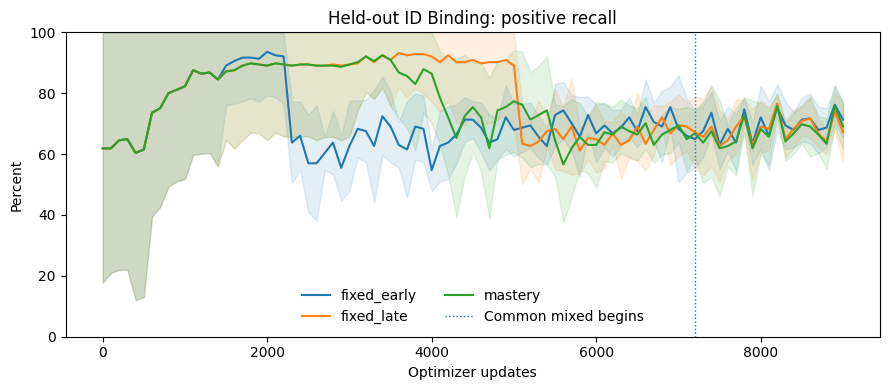

Saved: prediction_binding_positive_recall.png


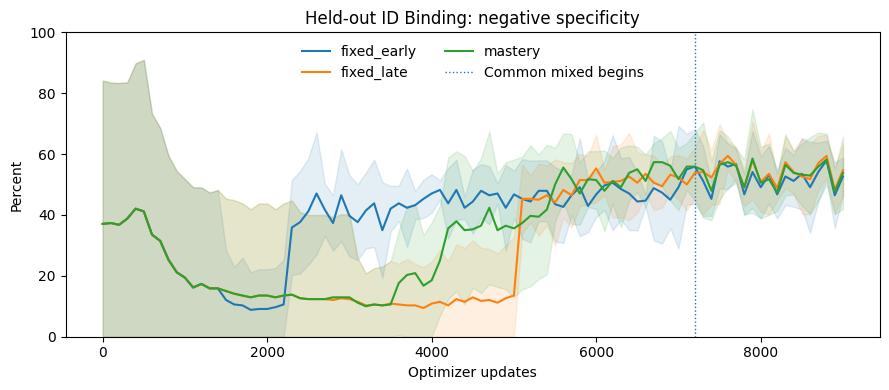

Saved: prediction_binding_negative_specificity.png


In [8]:
def plot_binding_rate(split, metric, title, path):
    data = checkpoint_metrics[(checkpoint_metrics["split"] == split) &
                              (checkpoint_metrics["task"] == "pair")]
    if data.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 4))
    for policy, rows in data.groupby("policy"):
        agg = rows.groupby("step")[metric].agg(["mean", "std"]).sort_index()
        x = agg.index.to_numpy(dtype=float)
        y = 100 * agg["mean"].to_numpy(dtype=float)
        sd = 100 * agg["std"].fillna(0).to_numpy(dtype=float)
        line, = ax.plot(x, y, label=policy)
        ax.fill_between(x, np.maximum(0, y - sd), np.minimum(100, y + sd),
                        color=line.get_color(), alpha=0.12)
    ax.set(title=title, xlabel="Optimizer updates", ylabel="Percent", ylim=(0, 100))
    ax.axvline(7200, linestyle=":", linewidth=1, label="Common mixed begins")
    ax.legend(frameon=False, ncol=2)
    plt.tight_layout()
    plt.savefig(path, dpi=180)
    plt.show()
    print("Saved:", path.name)

if not checkpoint_metrics.empty:
    plot_binding_rate("heldout_dev", "positive_recall",
                      "Held-out ID Binding: positive recall", BINDING_RECALL_FIG)
    plot_binding_rate("heldout_dev", "negative_specificity",
                      "Held-out ID Binding: negative specificity", BINDING_SPECIFICITY_FIG)


## 6. Which questions are difficult?

Use the dataset's scene metadata to examine Binding errors by held-out color–shape pair, object count, repeated attributes, and target shape. The same analysis covers Conjunction negatives where either the requested color or shape is missing.

Save per-seed results, then compare policies using **seed-level means**. The groups are descriptive; object count, repeated attributes, and OOD status may covary.

In [9]:
def build_question_metadata(rows):
    records = []
    for row in rows:
        task = row["template"]
        objects = row["scene"]["objects"]
        args = row["question"]["args"]
        colors = [obj["color"] for obj in objects]
        shapes = [obj["shape"] for obj in objects]
        color = args[0] if task in ("color", "conjunction", "pair") else ""
        shape = args[-1] if task in ("shape", "conjunction", "pair") else ""
        has_color, has_shape = color in colors, shape in shapes
        if task == "conjunction":
            case = ("positive" if has_color and has_shape else
                    "missing_color" if not has_color and has_shape else
                    "missing_shape" if has_color and not has_shape else "missing_both")
        elif task == "pair":
            case = "pair_present" if int(row["label"]) else "hard_negative"
        else:
            case = "not_applicable"
        records.append({"example_id": str(row["id"]), "task": task,
                        "label": int(row["label"]), "scene_id": str(row["scene_id"]),
                        "n_objects": len(objects), "n_colors": len(set(colors)),
                        "n_shapes": len(set(shapes)),
                        "repeated_color": len(set(colors)) < len(objects),
                        "repeated_shape": len(set(shapes)) < len(objects),
                        "target_color": color, "target_shape": shape,
                        "target_pair": f"{color}-{shape}" if task in ("pair", "conjunction") else "",
                        "question_case": case})
    return pd.DataFrame(records)

question_metadata = {}
if trace_blocks:
    id_meta = build_question_metadata(metadata_by_split["id_dev"])
    ood_meta = build_question_metadata(metadata_by_split["ood_dev"])
    question_metadata = {
        "id_dev": id_meta,
        "progress_dev": id_meta[id_meta["scene_id"].isin(progress_scenes)].reset_index(drop=True),
        "heldout_dev": id_meta[id_meta["scene_id"].isin(heldout_scenes)].reset_index(drop=True),
        "ood_dev": ood_meta,
    }
    for (seed, policy), blocks in trace_blocks.items():
        for split, block in blocks.items():
            if split not in question_metadata:
                continue
            if list(question_metadata[split]["example_id"]) != list(block["ids"]):
                raise ValueError(f"Question order does not match trace: {policy}, {seed}, {split}")

def evaluation_steps(run, block):
    steps = [int(x) for x in block["steps"]]
    into = next((int(x["step"]) for x in run["transitions"]
                 if x["to"] == "binding"), None)
    common = next((int(x["step"]) for x in run["transitions"]
                   if x["to"] == "common_mixed"), None)
    selected = {"final": steps[-1]}
    if into is not None:
        before = [s for s in steps if s <= into]
        after = [s for s in steps if s > into]
        if before: selected["before_binding"] = before[-1]
        if after: selected["after_binding"] = after[0]
    if common is not None:
        before = [s for s in steps if s <= common]
        if before: selected["end_binding"] = before[-1]
    return selected

GROUPS = ("n_objects", "repeated_color", "repeated_shape", "target_color",
          "target_shape", "target_pair", "question_case")
group_rows = []
run_lookup = {(int(r["seed"]), r["policy"]): r for r in runs}
for (seed, policy), blocks in trace_blocks.items():
    run = run_lookup[(seed, policy)]
    for split in ("heldout_dev", "ood_dev"):
        block = blocks.get(split)
        if block is None: continue
        meta = question_metadata[split]
        for checkpoint, step in evaluation_steps(run, block).items():
            i = int(np.flatnonzero(block["steps"] == step)[0])
            base = meta.copy()
            base["prediction"] = block["predictions"][i]
            base["probability_yes"] = block["probabilities"][i]
            for task in ("color", "shape", "conjunction", "pair"):
                task_rows = base[base["task"] == task]
                if task_rows.empty: continue
                groups = ["n_objects", "repeated_color", "repeated_shape"]
                groups += ["target_color"] if task == "color" else []
                groups += ["target_shape"] if task == "shape" else []
                groups += ["target_color", "target_shape", "target_pair", "question_case"] if task in ("pair", "conjunction") else []
                for group in groups:
                    for value, subset in task_rows.groupby(group, dropna=False):
                        stats = binary_scores(subset["label"], subset["prediction"],
                                              subset["probability_yes"])
                        group_rows.append({"seed": seed, "policy": policy, "split": split,
                                           "checkpoint": checkpoint, "step": step, "task": task,
                                           "group": group, "value": str(value), **stats})
error_groups = pd.DataFrame(group_rows)
if not error_groups.empty:
    error_groups.to_csv(ERROR_GROUP_CSV, index=False)
    print("Saved:", ERROR_GROUP_CSV.name)
    selected = error_groups[(error_groups["checkpoint"] == "final") &
                            (error_groups["task"] == "pair") &
                            (error_groups["group"].isin(["n_objects", "target_pair"]))]
    display(selected.groupby(["split", "group", "value", "policy"])["accuracy"]
            .agg(["mean", "std", "count"]).round(3))
else:
    print("Subgroup analysis requires recorded prediction traces.")


Saved: prediction_error_subgroups.csv


mean    std  count
split       group       value           policy                          
heldout_dev n_objects   3               fixed_early  0.637  0.067      5
                                        fixed_late   0.614  0.013      5
                                        mastery      0.633  0.019      5
                        4               fixed_early  0.600  0.060      5
                                        fixed_late   0.600  0.075      5
...                                                    ...    ...    ...
ood_dev     target_pair purple-triangle fixed_late   0.486  0.041      5
                                        mastery      0.506  0.025      5
                        red-crescent    fixed_early  0.494  0.065      5
                                        fixed_late   0.501  0.055      5
                                        mastery      0.492  0.029      5

[78 rows x 3 columns]

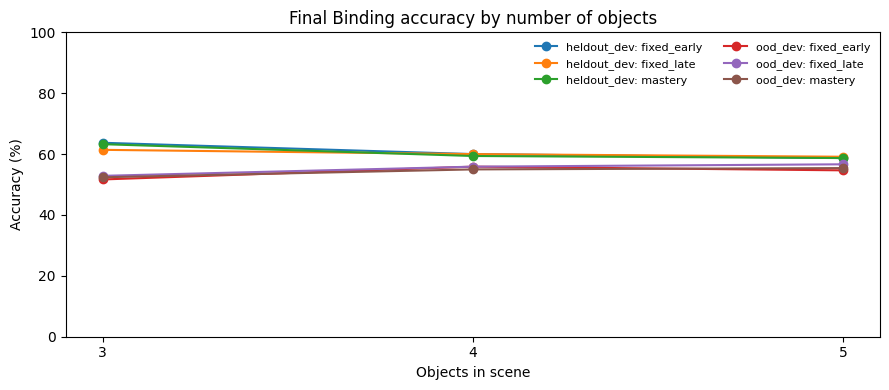

Saved: prediction_binding_by_object_count.png


In [10]:
if not error_groups.empty:
    plot_data = error_groups[(error_groups["checkpoint"] == "final") &
                             (error_groups["task"] == "pair") &
                             (error_groups["group"] == "n_objects")]
    if not plot_data.empty:
        fig, ax = plt.subplots(figsize=(9, 4))
        for (split, policy), rows in plot_data.groupby(["split", "policy"]):
            agg = rows.groupby("value")["accuracy"].agg(["mean", "std"]).sort_index()
            x = agg.index.astype(int).to_numpy()
            ax.plot(x, 100 * agg["mean"], marker="o", label=f"{split}: {policy}")
        ax.set(title="Final Binding accuracy by number of objects",
               xlabel="Objects in scene", ylabel="Accuracy (%)", ylim=(0, 100))
        ax.set_xticks(sorted({int(v) for v in plot_data["value"]}))
        ax.legend(frameon=False, ncol=2, fontsize=8)
        plt.tight_layout()
        plt.savefig(BINDING_COMPLEXITY_FIG, dpi=180)
        plt.show()
        print("Saved:", BINDING_COMPLEXITY_FIG.name)


## 7. How do errors change after entering Binding?

For the same questions immediately before and after the Binding transition, report false negatives and false positives separately. Then summarize **correct→incorrect**, **incorrect→correct**, and subsequent recovery by answer label and scene attributes. The comparisons are based on actual transition steps, not on an assumed common boundary.

In [11]:
transition_errors = []
if not questions.empty:
    relevant = questions[(questions["stage_to"] == "binding") &
                         (questions["split"].isin(("heldout_dev", "ood_dev")))].copy()
    context = pd.concat([question_metadata[name].assign(split=name)
                         for name in ("heldout_dev", "ood_dev")], ignore_index=True)
    context = context[["split", "example_id", "repeated_color", "repeated_shape"]]
    relevant = relevant.merge(context, on=["split", "example_id"],
                              how="left", validate="many_to_one")
    def add_category_summary(part, seed, policy, split, task, dimension, value):
        previously_right = int(part["before_correct"].sum())
        forgotten = int((part["category"] == "forgotten").sum())
        learned = int((part["category"] == "newly_learned").sum())
        row = {"seed": seed, "policy": policy, "split": split, "task": task,
               "group": dimension, "value": str(value), "n": len(part),
               "retained": int((part["category"] == "retained").sum()),
               "forgotten": forgotten, "newly_learned": learned,
               "still_incorrect": int((part["category"] == "still_incorrect").sum()),
               "churn": (forgotten + learned) / len(part),
               "forgetting_rate": forgotten / previously_right if previously_right else np.nan,
               "false_negative_before": int(((part["label"] == 1) &
                                             (part["before_prediction"] == 0)).sum()),
               "false_negative_after": int(((part["label"] == 1) &
                                            (part["after_prediction"] == 0)).sum()),
               "false_positive_before": int(((part["label"] == 0) &
                                             (part["before_prediction"] == 1)).sum()),
               "false_positive_after": int(((part["label"] == 0) &
                                            (part["after_prediction"] == 1)).sum())}
        if "recovered" in part:
            row["recovered"] = int(part["recovered"].sum())
            row["recovery_among_forgotten"] = (row["recovered"] / forgotten
                                                 if forgotten else np.nan)
        return row

    for (seed, policy, split, task), part in relevant.groupby(
        ["seed", "policy", "split", "task"]):
        transition_errors.append(add_category_summary(part, seed, policy, split, task, "all", "all"))
        fields = ["label", "n_objects", "repeated_color", "repeated_shape"]
        if task in ("pair", "conjunction"):
            fields += ["target_color", "target_shape"]
        for field in fields:
            for value, subgroup in part.groupby(field, dropna=False):
                transition_errors.append(add_category_summary(
                    subgroup, seed, policy, split, task, field, value))
transition_errors = pd.DataFrame(transition_errors)
if not transition_errors.empty:
    transition_errors.to_csv(ERROR_TRANSITION_CSV, index=False)
    print("Saved:", ERROR_TRANSITION_CSV.name)
    pair_label = transition_errors[(transition_errors["split"] == "heldout_dev") &
                                   (transition_errors["task"] == "pair") &
                                   (transition_errors["group"] == "label")]
    print("Binding question changes by true label (seed-level means):")
    display(pair_label.groupby(["policy", "value"])[
        ["churn", "forgetting_rate", "recovery_among_forgotten"]
    ].agg(["mean", "std"]).round(3))
    all_pair = transition_errors[(transition_errors["split"].isin(("heldout_dev", "ood_dev"))) &
                                 (transition_errors["task"] == "pair") &
                                 (transition_errors["group"] == "all")]
    print("Binding false-positive and false-negative changes (counts per seed):")
    display(all_pair.groupby(["split", "policy"])[
        ["false_negative_before", "false_negative_after",
         "false_positive_before", "false_positive_after"]].mean().round(1))
else:
    print("Transition error analysis requires recorded prediction traces.")


Saved: prediction_error_transitions.csv
Binding question changes by true label (seed-level means):


churn        forgetting_rate         \
                    mean    std            mean    std   
policy      value                                        
fixed_early 0      0.306  0.161           0.072  0.161   
            1      0.351  0.132           0.335  0.150   
fixed_late  0      0.424  0.073           0.112  0.252   
            1      0.385  0.142           0.360  0.128   
mastery     0      0.426  0.123           0.093  0.209   
            1      0.396  0.090           0.386  0.105   

                  recovery_among_forgotten         
                                      mean    std  
policy      value                                  
fixed_early 0                        0.444    NaN  
            1                        0.571  0.174  
fixed_late  0                        0.278    NaN  
            1                        0.479  0.172  
mastery     0                        0.143    NaN  
            1                        0.494  0.127

Binding false-positive and false-negative changes (counts per seed):


false_negative_before  false_negative_after  \
split       policy                                                     
heldout_dev fixed_early                    4.2                  19.2   
            fixed_late                     5.8                  19.4   
            mastery                        5.4                  21.6   
ood_dev     fixed_early                   25.2                  79.6   
            fixed_late                    48.0                 128.2   
            mastery                       44.4                 107.2   

                         false_positive_before  false_positive_after  
split       policy                                                    
heldout_dev fixed_early                   60.8                  43.6  
            fixed_late                    58.8                  37.2  
            mastery                       59.2                  35.8  
ood_dev     fixed_early                  174.6                 113.8  
            fixed_late                   151.8                  70.0  
            mastery                      152.0                  89.4

## Reading the outputs

- `mastery_transition_accuracy.csv`: aggregate changes around the recorded transitions.
- `prediction_change_summary.csv` and `prediction_changes_by_example.csv.gz`: matched-question correctness changes and recovery.
- `prediction_error_checkpoints.csv`: TP, FN, TN, FP, positive recall, negative specificity, predicted-positive rate, and BCE for each checkpoint.
- `prediction_error_subgroups.csv`: final and transition-adjacent errors by object count, target attributes, repeated attributes, and Conjunction error type.
- `prediction_error_transitions.csv`: changes in false positives/negatives and individual-question categories immediately after entering Binding.

Always compare policies across their **five seeds**, not by treating individual questions as independent repetitions. The old experiment's historical metrics remain unchanged, and this notebook does not train the model.